In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error

# Assignment 9

### 1.

Get the country-specific covid case data from `https://github.com/CSSEGISandData/COVID-19/blob/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv`

Pick a country. Let $Y_t$ be the case count for day $t$ since the outbreak onset for that country. That is, process the time series so that $t=0$ is the first day with more than 0 cases. Then, fit a distributed lag linear model as follows

$Y_t=\alpha_0+\beta_1Y_{t-1}+\beta_2Y_{t-2}+\beta_3Y_{t-3}+\beta_4Y_{t-4}+\beta_5Y_{t-5}+\epsilon_t$

That is, see how the last five days predicts the current day. Report and interpret the coefficients.

In [2]:
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/refs/heads/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
covid = pd.read_csv(url)

print(covid.shape)
covid

(289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.939110,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.153300,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.033900,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.506300,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.202700,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,NaN,West Bank and Gaza,31.952200,35.233200,0,0,0,0,0,0,...,703228,703228,703228,703228,703228,703228,703228,703228,703228,703228
285,NaN,Winter Olympics 2022,39.904200,116.407400,0,0,0,0,0,0,...,535,535,535,535,535,535,535,535,535,535
286,NaN,Yemen,15.552727,48.516388,0,0,0,0,0,0,...,11945,11945,11945,11945,11945,11945,11945,11945,11945,11945
287,NaN,Zambia,-13.133897,27.849332,0,0,0,0,0,0,...,343012,343012,343079,343079,343079,343135,343135,343135,343135,343135


In [3]:
us = covid[covid["Country/Region"] == "US"]

cases_cols = covid.columns[4:]
us_cases = us[cases_cols].sum(axis=0)

print("Cumulative cases:")
print(us_cases)

Cumulative cases:
1/22/20            1
1/23/20            1
1/24/20            2
1/25/20            2
1/26/20            5
             ...    
3/5/23     103646975
3/6/23     103655539
3/7/23     103690910
3/8/23     103755771
3/9/23     103802702
Length: 1143, dtype: int64


daily number of new cases between previous day $=Y_t=C_t-C_{t-1}$ where $C_t$ is the cumulative number of cases on day $t$

In [4]:
def prepare_country(cumulative):

    # calculate daily number of new cases between previous day
    daily = cumulative.diff()
    daily.iloc[0] = cumulative.iloc[0]

    data = pd.DataFrame({
        "date": daily.index,
        "Y": daily.to_numpy(dtype=float),
        "t": np.arange(len(daily))
    })

    return data.reset_index(drop=True)

A = prepare_country(us_cases)
print(A)

         date        Y     t
0     1/22/20      1.0     0
1     1/23/20      0.0     1
2     1/24/20      1.0     2
3     1/25/20      0.0     3
4     1/26/20      3.0     4
...       ...      ...   ...
1138   3/5/23  -3862.0  1138
1139   3/6/23   8564.0  1139
1140   3/7/23  35371.0  1140
1141   3/8/23  64861.0  1141
1142   3/9/23  46931.0  1142

[1143 rows x 3 columns]


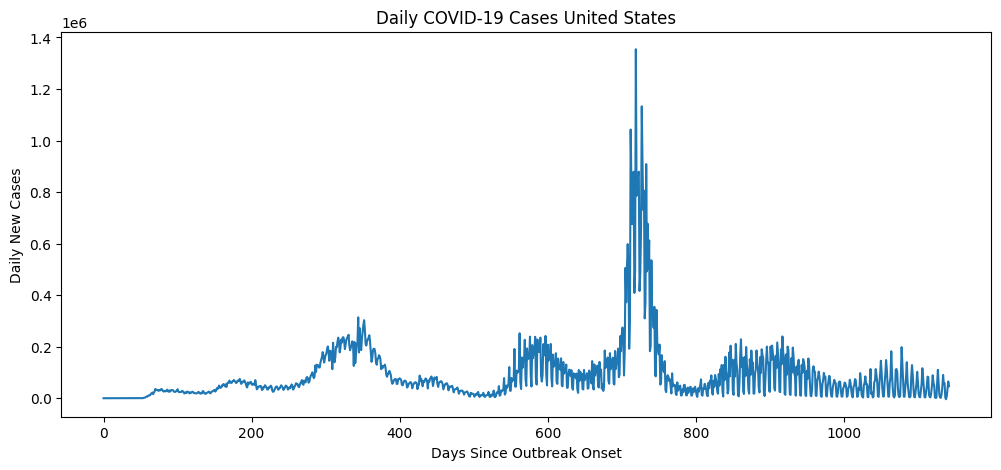

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(A["t"], A["Y"])

plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Daily New Cases")
plt.title("Daily COVID-19 Cases United States")
plt.show()

The multiple linear regression model will have 5 predictor variables:

$X_{1,t}=Y_{t-1}$

$X_{2,t}=Y_{t-2}$

$X_{3,t}=Y_{t-3}$

$X_{4,t}=Y_{t-4}$

$X_{5,t}=Y_{t-5}$

In [6]:
def create_lags(data):
    
    df = data.copy()
    for i in range(1, 6):
        df[f"lag{i}"] = df["Y"].shift(i)
        
    df = df.dropna().reset_index(drop=True)
    return df

A_lag = create_lags(A)
A_lag

,date,Y,t,lag1,lag2,lag3,lag4,lag5
0,1/27/20,0.0,5,3.0,0.0,1.0,0.0,1.0
1,1/28/20,0.0,6,0.0,3.0,0.0,1.0,0.0
2,1/29/20,1.0,7,0.0,0.0,3.0,0.0,1.0
3,1/30/20,0.0,8,1.0,0.0,0.0,3.0,0.0
4,1/31/20,2.0,9,0.0,1.0,0.0,0.0,3.0
...,...,...,...,...,...,...,...,...
1133,3/5/23,-3862.0,1138,2147.0,58933.0,55885.0,90417.0,43628.0
1134,3/6/23,8564.0,1139,-3862.0,2147.0,58933.0,55885.0,90417.0
1135,3/7/23,35371.0,1140,8564.0,-3862.0,2147.0,58933.0,55885.0
1136,3/8/23,64861.0,1141,35371.0,8564.0,-3862.0,2147.0,58933.0


In [7]:
X_A = A_lag[["lag1", "lag2", "lag3", "lag4", "lag5"]]
y_A = A_lag["Y"]
model_A = LinearRegression()
model_A.fit(X_A, y_A)

print(f"a_0: {model_A.intercept_}")
print(f"B_1: {model_A.coef_[0]:.6f}")
print(f"B_2: {model_A.coef_[1]:.6f}")
print(f"B_3: {model_A.coef_[2]:.6f}")
print(f"B_4: {model_A.coef_[3]:.6f}")
print(f"B_5: {model_A.coef_[4]:.6f}")

a_0: 6393.360319858155
B_1: 0.518364
B_2: -0.010440
B_3: 0.219675
B_4: 0.098838
B_5: 0.104307


$\hat Y_t=\hat\alpha_0+\hat\beta_1Y_{t-1}+\hat\beta_2Y_{t-2}+\hat\beta_3Y_{t-3}+\hat\beta_4Y_{t-4}+\hat\beta_5Y_{t-5}$

$\hat\alpha_0$ is the intercept and represents the expected number of cases when all five previous case counts are 0

Each lag coefficient $\hat\beta_t$ represents the expected change in today's number of cases for one additional case $t$ days prior with the other lags constant

## 2. 

Let A and B be your two countries. Create a plot of time versus prediction error for the following: a. fit the model on (all of) A and apply it to (all of) A to get the mean squared error, b. fit A on the first half of the time for A, apply it to the second half of A to get the mean squared error.

We can measure prediction error using the residual $e_t=Y_t-\hat Y_t$ where $Y_t$ is the observed daily case count and $\hat Y_t$ is the predicted daily case count

The mean squared error is $MSE=\frac{1}{n}\sum_{t=1}^{n}(Y_t-\hat Y_t)^2$

In [8]:
predict_all = model_A.predict(X_A)
residuals = y_A.to_numpy() - predict_all
mse = mean_squared_error(y_A, predict_all)

In [9]:
split = len(A_lag) // 2
X_train = X_A.iloc[:split]
X_test = X_A.iloc[split:]
y_train = y_A.iloc[:split]
y_test = y_A.iloc[split:]

model_half = LinearRegression()
model_half.fit(X_train, y_train)

predict_test = model_half.predict(X_test)
residuals_test = y_test.to_numpy() - predict_test
mse_test = mean_squared_error(y_test, predict_test)

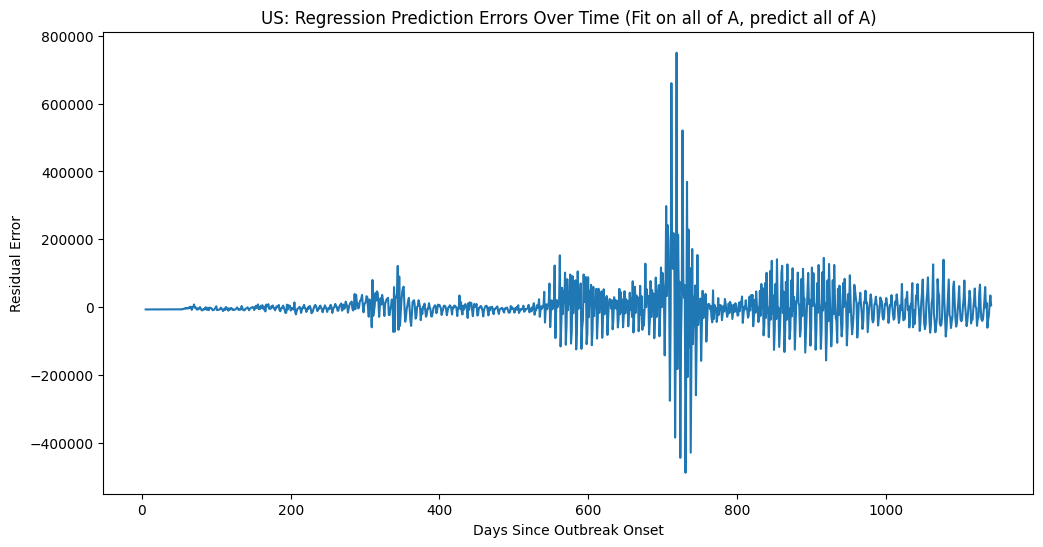

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(A_lag["t"], residuals)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("US: Regression Prediction Errors Over Time (Fit on all of A, predict all of A)")
plt.show()

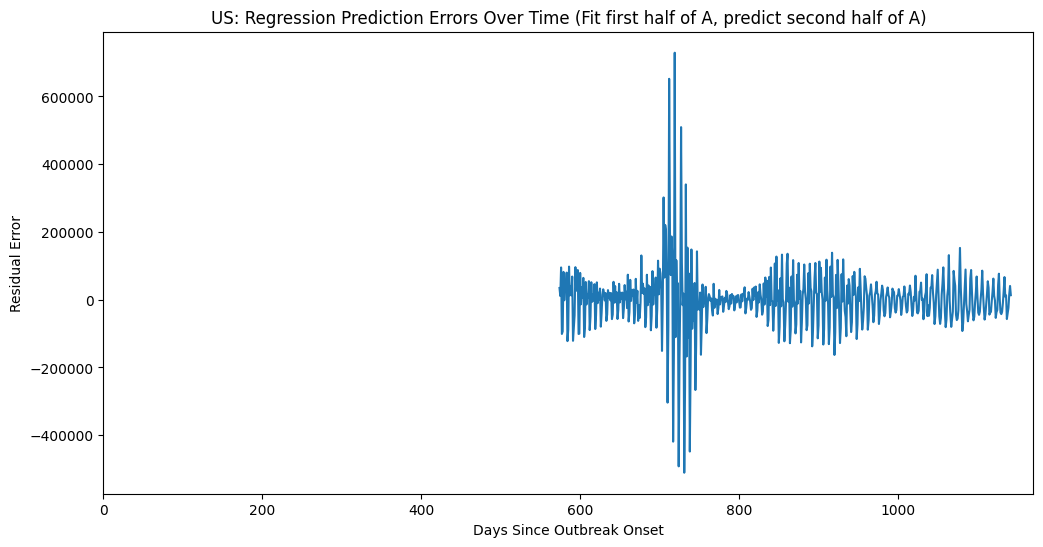

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(A_lag["t"].iloc[split:], residuals_test)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("US: Regression Prediction Errors Over Time (Fit first half of A, predict second half of A)")
plt.xlim(0, None)
plt.show()

In [12]:
print("MSE (all data):", mse)
print("MSE (fit 1st half of A, test 2nd half of A):", mse_test)

MSE (all data): 4116667734.5562906
MSE (fit 1st half of A, test 2nd half of A): 8025909480.660431


## 3.

Plot the errors over time for applying the model from country A and applying it to a new country, B, and report the mean squared error.

In [13]:
japan = covid[covid["Country/Region"] == "Japan"]
japan_cases = japan[cases_cols].sum(axis=0)
print("Cumulative cases:")
print(japan_cases)

Cumulative cases:
1/22/20           2
1/23/20           2
1/24/20           2
1/25/20           2
1/26/20           4
             ...   
3/5/23     33282370
3/6/23     33286633
3/7/23     33298799
3/8/23     33310604
3/9/23     33320438
Length: 1143, dtype: int64


In [14]:
B = prepare_country(japan_cases)
print(B)

         date        Y     t
0     1/22/20      2.0     0
1     1/23/20      0.0     1
2     1/24/20      0.0     2
3     1/25/20      0.0     3
4     1/26/20      2.0     4
...       ...      ...   ...
1138   3/5/23   8731.0  1138
1139   3/6/23   4263.0  1139
1140   3/7/23  12166.0  1140
1141   3/8/23  11805.0  1141
1142   3/9/23   9834.0  1142

[1143 rows x 3 columns]


In [15]:
B_lag = create_lags(B)
B_lag

,date,Y,t,lag1,lag2,lag3,lag4,lag5
0,1/27/20,0.0,5,2.0,0.0,0.0,0.0,2.0
1,1/28/20,3.0,6,0.0,2.0,0.0,0.0,0.0
2,1/29/20,0.0,7,3.0,0.0,2.0,0.0,0.0
3,1/30/20,4.0,8,0.0,3.0,0.0,2.0,0.0
4,1/31/20,4.0,9,4.0,0.0,3.0,0.0,2.0
...,...,...,...,...,...,...,...,...
1133,3/5/23,8731.0,1138,10431.0,10522.0,11506.0,13950.0,14792.0
1134,3/6/23,4263.0,1139,8731.0,10431.0,10522.0,11506.0,13950.0
1135,3/7/23,12166.0,1140,4263.0,8731.0,10431.0,10522.0,11506.0
1136,3/8/23,11805.0,1141,12166.0,4263.0,8731.0,10431.0,10522.0


In [16]:
X_B = B_lag[["lag1", "lag2", "lag3", "lag4", "lag5"]]
y_B = B_lag["Y"]
pred_B = model_A.predict(X_B)

residuals_B = y_B.to_numpy() - pred_B
mse_B = mean_squared_error(y_B, pred_B)

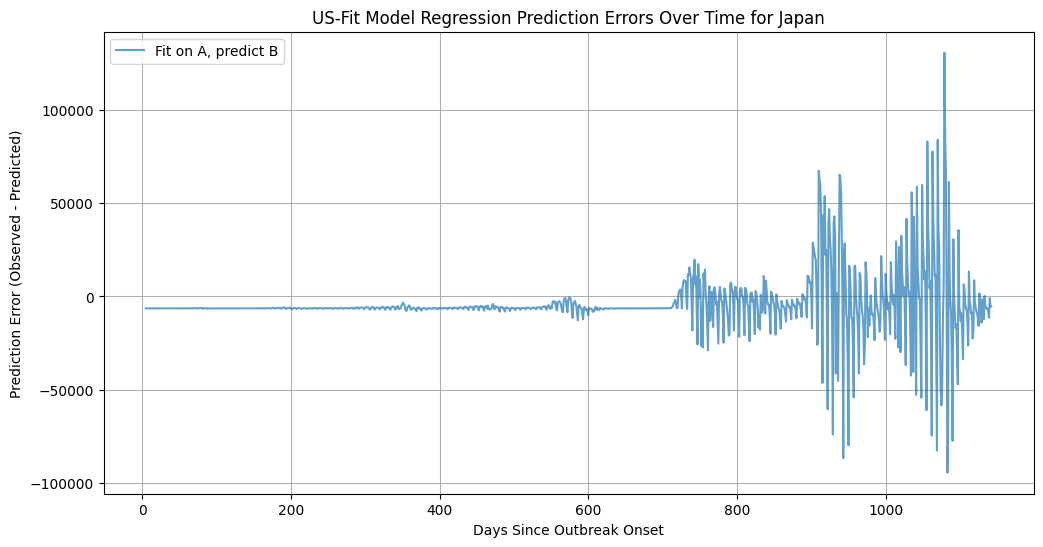

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(B_lag["t"], residuals_B, label="Fit on A, predict B", alpha=0.7)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Prediction Error (Observed - Predicted)")
plt.title("US-Fit Model Regression Prediction Errors Over Time for Japan")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
print("US model applied to Japan")
print("MSE:", mse_B)

US model applied to Japan
MSE: 260363439.62724012


## 4.

Let $Z_t=I(Y_t>Y_{t-1})$
. That is,$Z_t$
 is 1 if cases went up on da$t$ 
 a0d 
 otherwise. Consider the following Markovian logit m

$logit P(Z_t=1)=\alpha_0+\beta_1Z_{t-1}+\beta_2Z_{t-2}+\beta_3Z_{t-3}+\beta_4Z_{t-4}+\beta_5Z_{t-5}$

How does whether or not the previous five days case values predict whether or not the number of cases will go up or down? Report and interpret your coefficients.odel

The logit transformation is $logit(p)=\ln\left(\frac{p}{1-p}\right)$

The predicted probability is $P(Z_t=1)=\frac{e^{\eta_t}}{1+e^{\eta_t}}$ where $\eta_t=\alpha_0+\sum_{j=1}^{5}\beta_jZ_{t-j}$

In [19]:
A["Z"] = (A["Y"] > A["Y"].shift(1)).astype(float)

# day 1 has no previous day
A.loc[0, "Z"] = np.nan
A

,date,Y,t,Z
0,1/22/20,1.0,0,NaN
1,1/23/20,0.0,1,0.0
2,1/24/20,1.0,2,1.0
3,1/25/20,0.0,3,0.0
4,1/26/20,3.0,4,1.0
...,...,...,...,...
1138,3/5/23,-3862.0,1138,0.0
1139,3/6/23,8564.0,1139,1.0
1140,3/7/23,35371.0,1140,1.0
1141,3/8/23,64861.0,1141,1.0


The logistic regression model will have 5 binary lagged variables

$Z_{t-1},Z_{t-2},Z_{t-3},Z_{t-4},Z_{t-5}$

In [20]:
A[f"Z_lag{1}"] = A["Z"].shift(1)
A[f"Z_lag{2}"] = A["Z"].shift(2)
A[f"Z_lag{3}"] = A["Z"].shift(3)
A[f"Z_lag{4}"] = A["Z"].shift(4)
A[f"Z_lag{5}"] = A["Z"].shift(5)

A = A.dropna().reset_index(drop=True)
A

,date,Y,t,Z,Z_lag1,Z_lag2,Z_lag3,Z_lag4,Z_lag5
0,1/28/20,0.0,6,0.0,0.0,1.0,0.0,1.0,0.0
1,1/29/20,1.0,7,1.0,0.0,0.0,1.0,0.0,1.0
2,1/30/20,0.0,8,0.0,1.0,0.0,0.0,1.0,0.0
3,1/31/20,2.0,9,1.0,0.0,1.0,0.0,0.0,1.0
4,2/1/20,0.0,10,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
1132,3/5/23,-3862.0,1138,0.0,0.0,1.0,0.0,1.0,1.0
1133,3/6/23,8564.0,1139,1.0,0.0,0.0,1.0,0.0,1.0
1134,3/7/23,35371.0,1140,1.0,1.0,0.0,0.0,1.0,0.0
1135,3/8/23,64861.0,1141,1.0,1.0,1.0,0.0,0.0,1.0


In [21]:
X_logit = A[["Z_lag1", "Z_lag2", "Z_lag3", "Z_lag4", "Z_lag5"]]
y_logit = A["Z"].astype(int)

logit_model = LogisticRegression()
logit_model.fit(X_logit, y_logit)

print(f"a_0: {logit_model.intercept_[0]}")
print(f"B_1: {logit_model.coef_[0][0]}")
print(f"B_2: {logit_model.coef_[0][1]}")
print(f"B_3: {logit_model.coef_[0][2]}")
print(f"B_4: {logit_model.coef_[0][3]}")
print(f"B_5: {logit_model.coef_[0][4]}")

a_0: 1.3075053051061587
B_1: -0.490654702875713
B_2: -0.16594521588998903
B_3: -0.8155076208986393
B_4: -1.0137375733484748
B_5: -0.21279590564539508


$\alpha_0$ is the intercept and represents the log-odds that cases increase today when none of the prior 5 days increased

The coefficients $\beta_j$ measure the difference in log-odds of an increase today when cases increased $j$ days ago compared with when they did not with the other indicators constant

The coefficient for lag 1 is -0.4907 which is an odds ratio of about 0.612 meaning an increase yesterday is associated with about 38.8% lower odds of an increase today